
Project Title: Deep Learning for Automated Cell Counting in Microscopy Images

Team Member:
Amy Seo (jungmin.seo.manchester@gmail.com)
Dingshan Deng (dingshandeng@gmail.com)
Pranjal Singh (singhp19@msu.edu)
Ruiping Huang (rhuang26@uic.edu)


Dataset: https://universe.roboflow.com/cell-counting/cell-counting-zeqo5/browse?queryText=&pageSize=100&startingIndex=0&browseQuery=true$0


## Installing Packages

In [1]:
!pip install roboflow

## Importing packages

In [59]:
from google.colab import userdata
from roboflow import Roboflow
import os
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import cv2

## Getting the data

In [3]:
api_key = userdata.get("ROBOFLOW_API_KEY") #key acquired from roboflow universe

In [4]:
rf = Roboflow(api_key=api_key) # *---- Add api key to secrect w name ROBOFLOW_API_KEY ----*
project = rf.workspace("pranjal-singh-evqc5").project(
    "cell-counting-zeqo5-raras"  # *-------- Need to change this to specific dir --------*
)

version = project.version(1) #version generated on roboflow universe
dataset = version.download("coco") #chose this formar for PyTorch compatibality

loading Roboflow workspace...
loading Roboflow project...


## Exploring data location and files

In [5]:
print(type(dataset))
print(dataset.name)
dataset_path = dataset.location #need the location to find subfolders
print(dataset.location)
print(dataset.model_format) #double checking if format is correct

print(os.listdir(dataset_path)) #all subfolders & files in dataset

for folder in ['train', 'valid', 'test']:
    folder_path = os.path.join(dataset_path, folder)
    if os.path.exists(folder_path):
        print(f"Total files {folder}: {len(os.listdir(folder_path))}")

<class 'roboflow.core.dataset.Dataset'>
cell counting
/content/cell-counting-1
coco
['train', 'README.roboflow.txt', 'valid', 'test']
Total files train: 351
Total files valid: 101
Total files test: 51


## Inspecting README

In [6]:
# with open(os.path.join(dataset_path,"README.roboflow.txt"),"r") as f: #inspecting read me
#   readme_text = f.read()

# print(readme_text)

## File types

In [7]:
data_dir = Path(dataset_path + "/train") #path to train dir
file_types = {file.suffix.lower() for file in data_dir.rglob("*") if file.is_file() and file.suffix} #all file types  (from ai)

print(f"File types found in directory: {[ext for ext in file_types]}") #.jpg files are images and .json is labels

json_file = [file.name for file in data_dir.glob("*.json") if file.is_file()]
print(f"Json file (w/labels) name: {json_file[0]}") #json file wiht training labels

with open(data_dir/Path(json_file[0]),"r") as file:
  data = json.load(file)

# print(json.dumps(data, indent=4))

ann_df = pd.DataFrame(data["annotations"])
img_df = pd.DataFrame(data["images"])
cat_df = pd.DataFrame(data["categories"])
img_df.head()

File types found in directory: ['.json', '.jpg']
Json file (w/labels) name: _annotations.coco.json


,id,license,file_name,height,width,date_captured,extra
0,0,1,2022_12_7_1_B-creport_275_jpg.rf.545fabe9f21ea...,640,640,2026-10-06T16:32:03+00:00,{'name': '2022_12_7_1_B-creport_275.jpg'}
1,1,1,2022_12_7_1_B-creport_267_jpg.rf.e2f9c2899dd93...,640,640,2026-10-06T16:32:03+00:00,{'name': '2022_12_7_1_B-creport_267.jpg'}
2,2,1,2022_12_7_2_B-creport_526_jpg.rf.4e10939bc6e3b...,640,640,2026-10-06T16:32:03+00:00,{'name': '2022_12_7_2_B-creport_526.jpg'}
3,3,1,2022_12_7_1_B-creport_272_jpg.rf.804d9e0436218...,640,640,2026-10-06T16:32:03+00:00,{'name': '2022_12_7_1_B-creport_272.jpg'}
4,4,1,2022_12_7_1_B-creport_271_jpg.rf.21a473e49f08f...,640,640,2026-10-06T16:32:03+00:00,{'name': '2022_12_7_1_B-creport_271.jpg'}


In [8]:
cat_df.head()

,id,name,supercategory
0,0,cell,none
1,1,Dead,cell
2,2,Live,cell


In [9]:
ann_df.head()

,id,image_id,category_id,bbox,iscrowd,area,segmentation
0,1,0,2,"[301, 17, 30, 30]",0,900.00,[]
1,2,0,2,"[329, 45, 25.5, 25.5]",0,650.25,[]
2,3,0,2,"[150, 15, 30, 27.5]",0,825.00,[]
3,4,0,2,"[111, 39, 34, 27.5]",0,935.00,[]
4,5,0,2,"[81, 60, 25.5, 23.5]",0,599.25,[]


# Exploratory Data Analysis (EDA)

In [10]:
cells_per_image = ann_df.groupby("image_id").size().rename("n_cells") #need to group all cells in a single image
cells_per_image.head()

,n_cells
image_id,
0,60
1,82
2,42
3,83
4,82


In [11]:
counts = (
    img_df[["id", "file_name","height","width"]].rename(columns={"id": "image_id"})
    .merge(cells_per_image, on="image_id", how="left")
    .fillna({"n_cells": 0})
    .astype({"n_cells": int})
) #creating a new dataset with id, # of cells and file name

counts.head()

,image_id,file_name,height,width,n_cells
0,0,2022_12_7_1_B-creport_275_jpg.rf.545fabe9f21ea...,640,640,60
1,1,2022_12_7_1_B-creport_267_jpg.rf.e2f9c2899dd93...,640,640,82
2,2,2022_12_7_2_B-creport_526_jpg.rf.4e10939bc6e3b...,640,640,42
3,3,2022_12_7_1_B-creport_272_jpg.rf.804d9e0436218...,640,640,83
4,4,2022_12_7_1_B-creport_271_jpg.rf.21a473e49f08f...,640,640,82


In [12]:
counts.describe()

,image_id,height,width,n_cells
count,350.000000,350.0,350.0,350.000000
mean,174.500000,640.0,640.0,53.091429
std,101.180532,0.0,0.0,14.921867
min,0.000000,640.0,640.0,23.000000
25%,87.250000,640.0,640.0,41.000000
50%,174.500000,640.0,640.0,52.000000
75%,261.750000,640.0,640.0,66.000000
max,349.000000,640.0,640.0,91.000000


In [13]:
counts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   image_id   350 non-null    int64 
 1   file_name  350 non-null    object
 2   height     350 non-null    int64 
 3   width      350 non-null    int64 
 4   n_cells    350 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 13.8+ KB


In [14]:
ann_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18582 entries, 0 to 18581
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            18582 non-null  int64  
 1   image_id      18582 non-null  int64  
 2   category_id   18582 non-null  int64  
 3   bbox          18582 non-null  object 
 4   iscrowd       18582 non-null  int64  
 5   area          18582 non-null  float64
 6   segmentation  18582 non-null  object 
dtypes: float64(1), int64(4), object(2)
memory usage: 1016.3+ KB


In [15]:
cat_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id             3 non-null      int64 
 1   name           3 non-null      object
 2   supercategory  3 non-null      object
dtypes: int64(1), object(2)
memory usage: 204.0+ bytes


## Examples of data

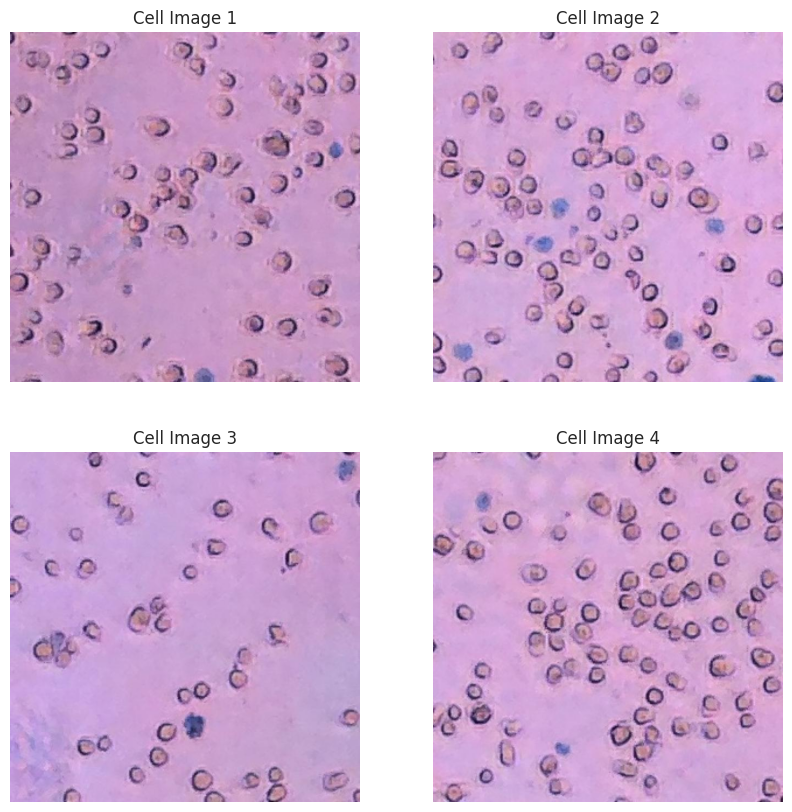

In [79]:
file_names = [data_dir/Path(file) for file in counts.head()["file_name"]]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flatten()

for i, img_path in enumerate(file_names[:4]): #displaying four images
    img = mpimg.imread(img_path)
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"Cell Image {i+1}")

plt.show()

## Nans in data

In [17]:
counts.isna().sum() #doesn't seem like there are any nans

,0
image_id,0
file_name,0
height,0
width,0
n_cells,0


## Height and width of images

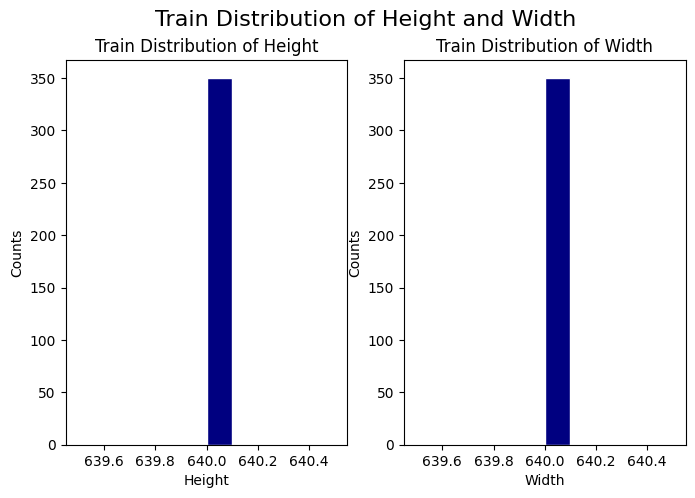

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(8, 5))
axes = axes.flatten()

axes[0].hist(counts["height"], bins=10, color="navy", edgecolor="white")
axes[0].set_xlabel("Height")
axes[0].set_ylabel("Counts")
axes[0].set_title("Train Distribution of Height")

axes[1].hist(counts["width"], bins=10, color="navy", edgecolor="white")
axes[1].set_xlabel("Width")
axes[1].set_ylabel("Counts")
axes[1].set_title("Train Distribution of Width")

plt.suptitle("Train Distribution of Height and Width", fontsize=16)
plt.show()

## Looking at label distribution

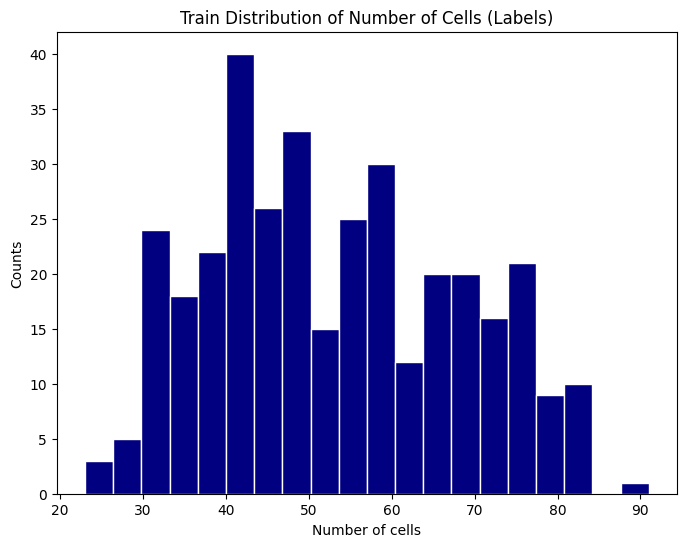

In [19]:
fig, ax =  plt.subplots(figsize=(8, 6))

ax.hist(counts["n_cells"], bins=20, color="navy", edgecolor="white")
ax.set_xlabel("Number of cells")
ax.set_ylabel("Counts")
ax.set_title("Train Distribution of Number of Cells (Labels)")
plt.show()

## Looking at live vs dead cells


In [24]:
#since we're not looking into live vs dead cells, their presence could be problematic

dead_id = cat_df.loc[cat_df["name"].str.lower() == "dead", "id"].iloc[0] #number of dead cells
live_id = cat_df.loc[cat_df["name"].str.lower() == "live", "id"].iloc[0] #number of live cells

dead_per_image = (
    ann_df[ann_df["category_id"] == dead_id]
    .groupby("image_id").size()
    .rename("n_dead")
)

live_per_image = (
    ann_df[ann_df["category_id"] == live_id]
    .groupby("image_id").size()
    .rename("n_dead")
)

dead_per_image.head()

,n_dead
image_id,
0,2
1,6
2,3
3,2
4,3


In [34]:
cells = ann_df.merge(
    cat_df[["id", "name"]].rename(columns={"id": "category_id", "name": "category"}),
    on="category_id",
)

live_area = cells.loc[cells["category"].str.lower() == "live", "area"]
dead_area = cells.loc[cells["category"].str.lower() == "dead", "area"]

bins = np.linspace(cells["area"].min(), cells["area"].max(), 40)


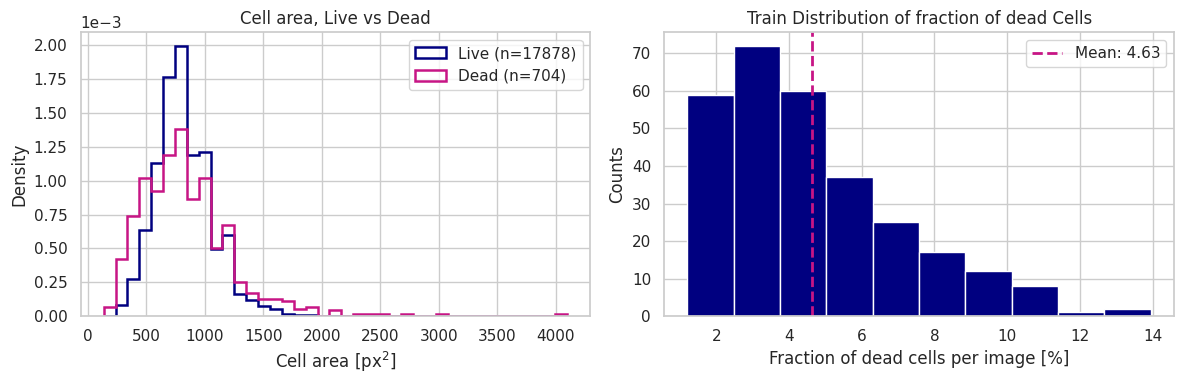

In [44]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes.flatten()
fraction_dead = (dead_per_image/(live_per_image+dead_per_image))*100
fraction_dead_mean = fraction_dead.mean()
ax[0].hist(live_area, bins=bins, density=True, histtype="step", linewidth=1.8, label=f"Live (n={len(live_area)})",color="navy")
ax[0].hist(dead_area, bins=bins, density=True, histtype="step", linewidth=1.8, label=f"Dead (n={len(dead_area)})",color="mediumvioletred")
ax[0].set_xlabel(r"Cell area [px$^2$]")
ax[0].set_ylabel("Density")
ax[0].set_title("Cell area, Live vs Dead")
ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax[0].legend()

ax[1].hist(fraction_dead, bins=10, color="navy", edgecolor="white")
ax[1].axvline(fraction_dead_mean, color="mediumvioletred", linestyle="dashed", linewidth=2, label=f"Mean: {fraction_dead_mean:.2f}")
ax[1].set_xlabel("Fraction of dead cells per image [%]")
ax[1].set_ylabel("Counts")
ax[1].set_title("Train Distribution of fraction of dead Cells")
ax[1].legend()

plt.tight_layout()
plt.show()

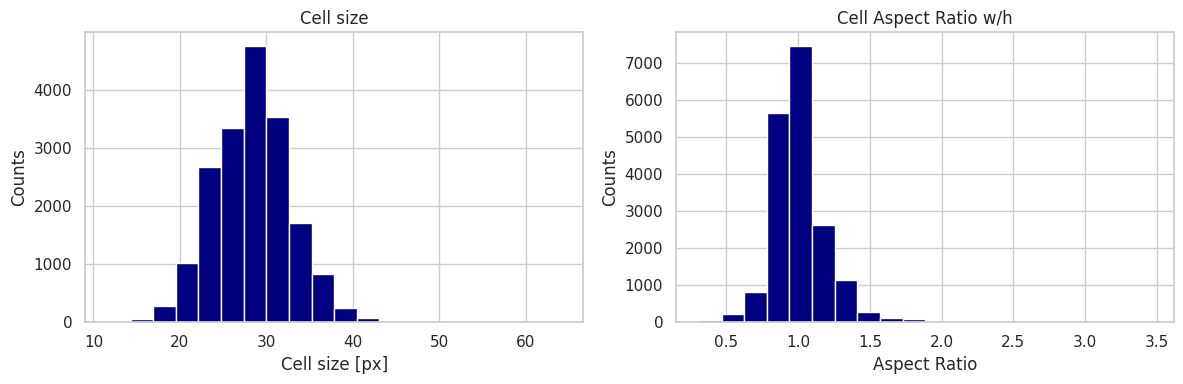

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes.flatten()
ax[0].hist(np.sqrt(ann_df["area"]), bins=20,color="navy")
ax[0].set_xlabel(r"Cell size [px]")
ax[0].set_ylabel("Counts")
ax[0].set_title("Cell size")

w = np.array(ann_df["bbox"].str[2])
h = np.array(ann_df["bbox"].str[3])

ax[1].hist(w/h, bins=20,color="navy")
ax[1].set_xlabel(r"Aspect Ratio")
ax[1].set_ylabel("Counts")
ax[1].set_title("Cell Aspect Ratio w/h")

plt.tight_layout()
plt.show()

## Image quality

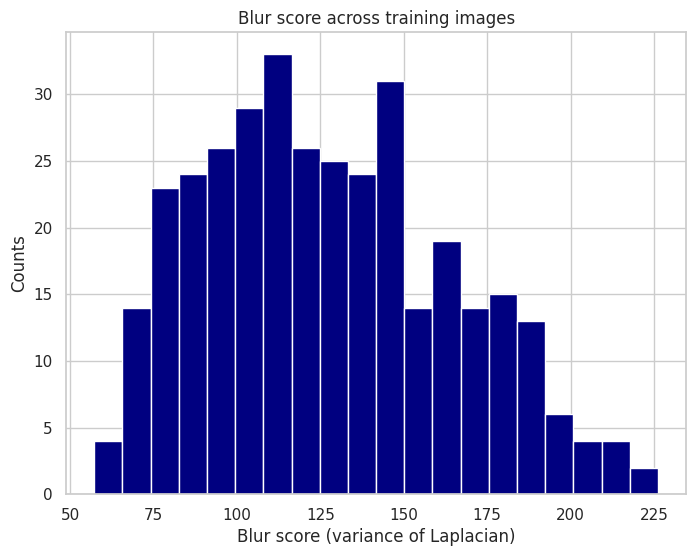

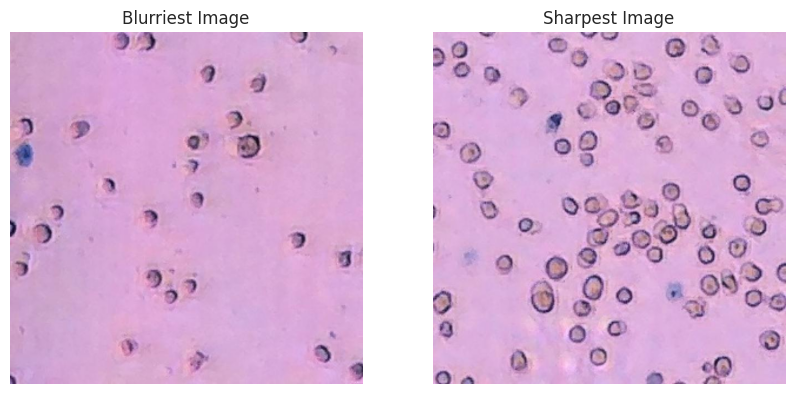

In [78]:
blur_path = ["",""]

blur_score_ls = [np.inf,0]

def blur_score(path):
    path = str(path)
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    score = cv2.Laplacian(img, cv2.CV_64F).var()
    if score < blur_score_ls[0]:
        blur_score_ls[0] = score
        blur_path[0] = path
    elif score > blur_score_ls[1]:
        blur_score_ls[1] = score
        blur_path[1] = path

    return score

counts["blur"] = [blur_score(data_dir / f) for f in counts["file_name"]]

fig, ax =  plt.subplots(figsize=(8, 6))
ax.hist(counts["blur"], bins=20,color="navy")
ax.set_xlabel("Blur score (variance of Laplacian)")
ax.set_ylabel("Counts")
ax.set_title("Blur score across training images")

plt.show()
print() #for spacing

fig, axes = plt.subplots(1, 2, figsize=(10, 10))
axes = axes.flatten()
img_1 = mpimg.imread(blur_path[0])
img_2 = mpimg.imread(blur_path[1])
axes[0].imshow(img_1)
axes[0].axis('off')
axes[0].set_title(f"Blurriest Image")
axes[1].imshow(img_2)
axes[1].axis('off')
axes[1].set_title(f"Sharpest Image")

plt.show()

## Overlap between cells

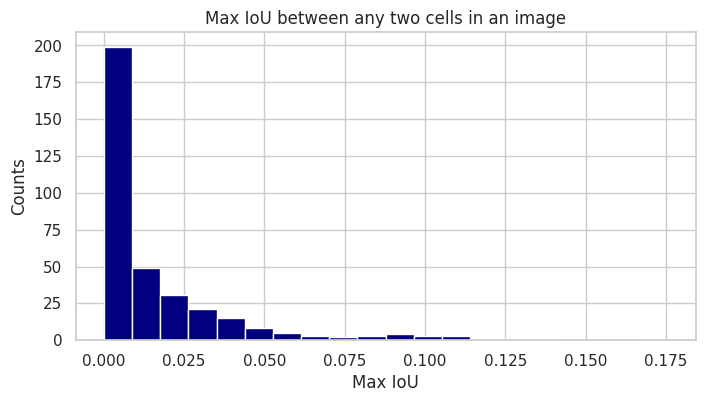

In [98]:
def iou(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = a[2] * a[3] + b[2] * b[3] - inter
    return inter / union

results = []
for image_id, g in ann_df.groupby("image_id"):
    boxes = g["bbox"].values
    ious = []
    for i in range(len(boxes)):
        for j in range(i + 1, len(boxes)): #going through each pair to compare cell boxes [x,y,w,h]
            ious.append(iou(boxes[i], boxes[j]))
    ious = np.array(ious)
    if len(ious) > 0:
      results.append(ious.max())
    else:
      results.append(-1) #to ensure we are not populate 0 because of this condition

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(results, bins=20, color="navy")
ax.set_xlabel("Max IoU")
ax.set_ylabel("Counts")
ax.set_title("Max IoU between any two cells in an image")
plt.show()

## Looking at "shades" of images

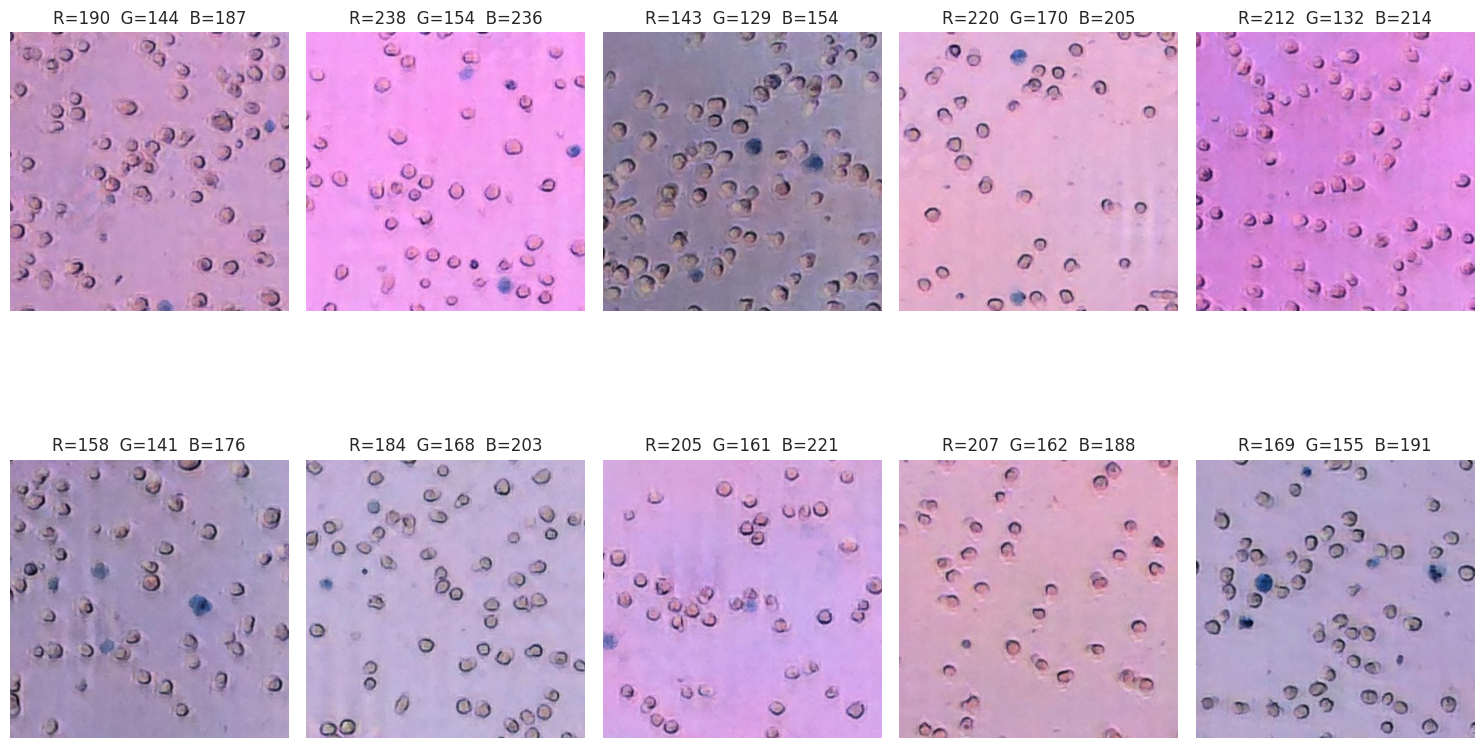

In [107]:
def mean_color(path):
    img = cv2.imread(str(path))
    return img.mean(axis=(0, 1))[::-1]       # flip to R, G, B

counts[["R", "G", "B"]] = np.array([mean_color(data_dir / f) for f in counts["file_name"]])  #getting r,g,b columns for each image

k = 10 #number of images to compare with (how fine of a comparison between images)
rgb = counts[["R", "G", "B"]].to_numpy() #converting to N x 3 numpy array

picked = [0] # start with the first image
for _ in range(k - 1):
    # distance from every image to its closest already-picked image
    dists = np.min([np.linalg.norm(rgb - rgb[p], axis=1) for p in picked], axis=0)
    picked.append(dists.argmax()) # take the one farthest from all picks

fig, axes = plt.subplots(2, k//2, figsize=(15, 10))
for ax, i in zip(axes.flatten(), picked):
    row = counts.iloc[i]
    ax.imshow(mpimg.imread(data_dir / row["file_name"]))
    ax.set_title(f"R={row['R']:.0f}  G={row['G']:.0f}  B={row['B']:.0f}")
    ax.axis("off")
plt.tight_layout()
plt.show()